<a href="https://colab.research.google.com/github/estewe2610/Detective-de-Se-ales/blob/main/Detective%20de%20Se%C3%B1ales%20Completo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, Input

print("Entorno configurado correctamente. Versión de TensorFlow:", tf.__version__)

Entorno configurado correctamente. Versión de TensorFlow: 2.21.0


In [3]:
# Parámetros globales de la señal
fs = 1000          # Frecuencia de muestreo (Hz)
fc = 100           # Frecuencia portadora (Hz)
Rs = 10            # Tasa de símbolos (baudios)
num_simbolos = 10  # Cantidad de símbolos por cada muestra

sps = int(fs / Rs)              # Muestras por símbolo (100 muestras)
total_muestras = sps * num_simbolos # Longitud total de cada señal (1000 puntos)
t = np.linspace(0, num_simbolos / Rs, total_muestras, endpoint=False)

print(f"Frecuencia de muestreo (fs): {fs} Hz")
print(f"Frecuencia portadora (fc): {fc} Hz")
print(f"Tasa de símbolos (Rs): {Rs} baudios")
print(f"Longitud total de cada señal: {total_muestras} muestras")

Frecuencia de muestreo (fs): 1000 Hz
Frecuencia portadora (fc): 100 Hz
Tasa de símbolos (Rs): 10 baudios
Longitud total de cada señal: 1000 muestras


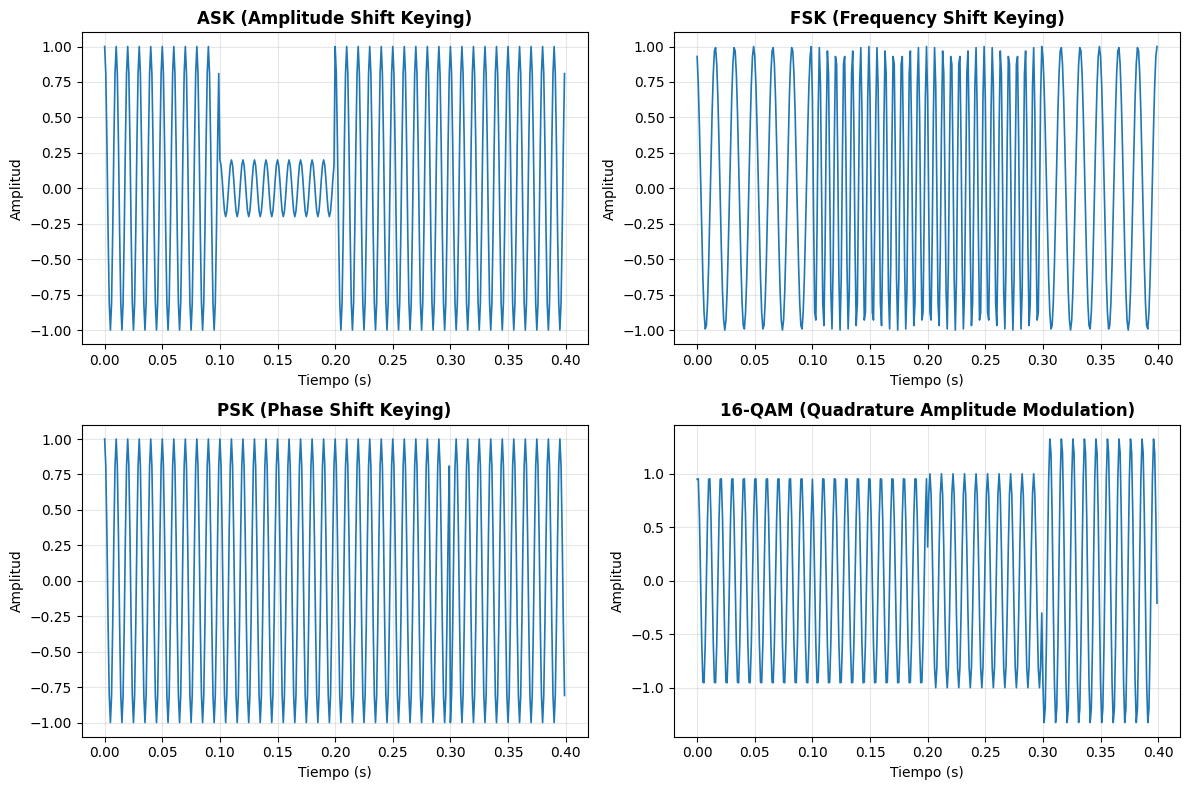

In [4]:
def generar_ask():
    bits = np.random.randint(0, 2, num_simbolos)
    amplitud = np.repeat(bits, sps)
    # Bit 1 = amplitud 1.0, Bit 0 = amplitud 0.2 (para distinguirla del ruido puro)
    envolvente = np.where(amplitud == 1, 1.0, 0.2)
    return envolvente * np.cos(2 * np.pi * fc * t)

def generar_fsk():
    bits = np.random.randint(0, 2, num_simbolos)
    f1 = fc + 40  # Frecuencia para bit 1 (140 Hz)
    f0 = fc - 40  # Frecuencia para bit 0 (60 Hz)
    frecuencias = np.repeat(np.where(bits == 1, f1, f0), sps)
    # Fase continua integrando la frecuencia instantánea
    fase = 2 * np.pi * np.cumsum(frecuencias) / fs
    return np.cos(fase)

def generar_psk():
    bits = np.random.randint(0, 2, num_simbolos)
    # BPSK: Bit 1 = fase 0°, Bit 0 = fase 180° (pi radianes)
    fases = np.repeat(np.where(bits == 1, 0, np.pi), sps)
    return np.cos(2 * np.pi * fc * t + fases)

def generar_16qam():
    # Niveles PAM-4 para componentes I y Q: {-3, -1, 1, 3} normalizados
    niveles = np.array([-3, -1, 1, 3]) / np.sqrt(10)
    I = np.repeat(np.random.choice(niveles, num_simbolos), sps)
    Q = np.repeat(np.random.choice(niveles, num_simbolos), sps)
    return I * np.cos(2 * np.pi * fc * t) - Q * np.sin(2 * np.pi * fc * t)

# Visualización de las 4 modulaciones limpias (solo los primeros 400 puntos para apreciarlos mejor)
plt.figure(figsize=(12, 8))
senales_demo = [
    (generar_ask(), "ASK (Amplitude Shift Keying)"),
    (generar_fsk(), "FSK (Frequency Shift Keying)"),
    (generar_psk(), "PSK (Phase Shift Keying)"),
    (generar_16qam(), "16-QAM (Quadrature Amplitude Modulation)")
]

for i, (sig, titulo) in enumerate(senales_demo, 1):
    plt.subplot(2, 2, i)
    plt.plot(t[:400], sig[:400], linewidth=1.2)
    plt.title(titulo, fontweight='bold')
    plt.xlabel("Tiempo (s)")
    plt.ylabel("Amplitud")
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

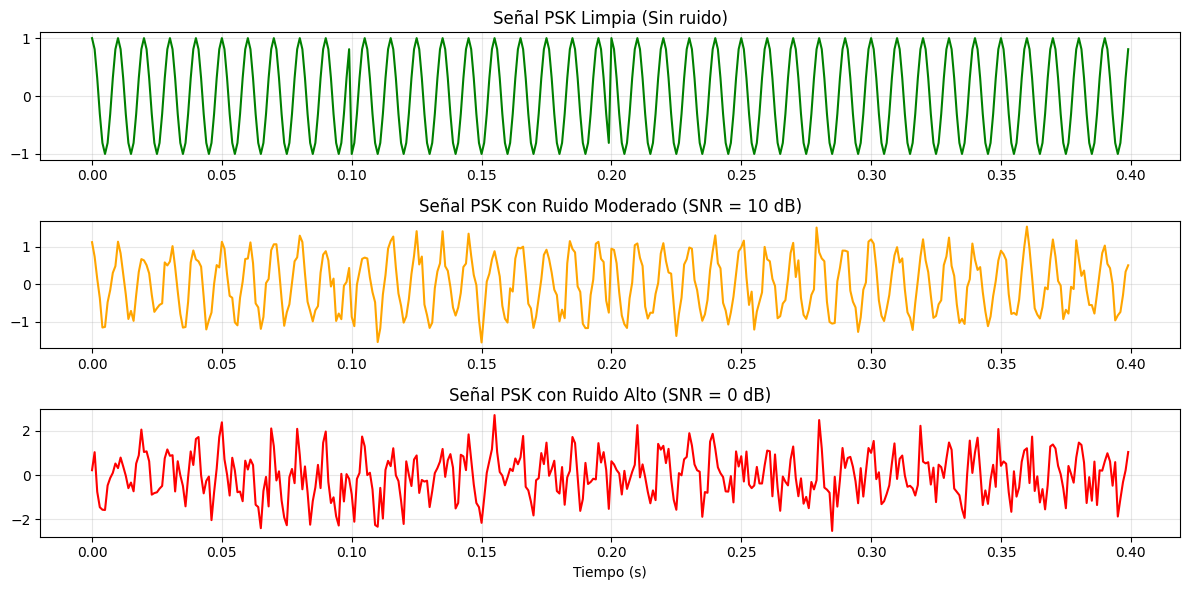

In [5]:
def agregar_awgn(senal, snr_db):
    potencia_senal = np.mean(senal ** 2)
    snr_lineal = 10 ** (snr_db / 10)
    potencia_ruido = potencia_senal / snr_lineal
    ruido = np.random.normal(0, np.sqrt(potencia_ruido), size=senal.shape)
    return senal + ruido

# Comparativa visual de una señal PSK con distintos niveles de ruido
senal_limpia = generar_psk()
senal_10db = agregar_awgn(senal_limpia, 10)
senal_0db = agregar_awgn(senal_limpia, 0)

plt.figure(figsize=(12, 6))
plt.subplot(3, 1, 1)
plt.plot(t[:400], senal_limpia[:400], color='green')
plt.title("Señal PSK Limpia (Sin ruido)")
plt.grid(True, alpha=0.3)

plt.subplot(3, 1, 2)
plt.plot(t[:400], senal_10db[:400], color='orange')
plt.title("Señal PSK con Ruido Moderado (SNR = 10 dB)")
plt.grid(True, alpha=0.3)

plt.subplot(3, 1, 3)
plt.plot(t[:400], senal_0db[:400], color='red')
plt.title("Señal PSK con Ruido Alto (SNR = 0 dB)")
plt.xlabel("Tiempo (s)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
muestras_por_clase = 1000
niveles_snr = [-5, 0, 5, 10, 15, 20]  # Variaciones de ruido en dB

X = []
y = []

generadores = [generar_ask, generar_fsk, generar_psk, generar_16qam]

for etiqueta, func_generadora in enumerate(generadores):
    for _ in range(muestras_por_clase):
        senal = func_generadora()
        snr_aleatorio = np.random.choice(niveles_snr)
        senal_con_ruido = agregar_awgn(senal, snr_aleatorio)

        X.append(senal_con_ruido)
        y.append(etiqueta)

X = np.array(X)
y = np.array(y)

# Separación estratificada: 80% Entrenamiento, 20% Prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Dataset generado exitosamente:")
print("Forma de X_train (Entrenamiento):", X_train.shape)
print("Forma de y_train (Etiquetas Entrenamiento):", y_train.shape)
print("Forma de X_test (Prueba):", X_test.shape)
print("Forma de y_test (Etiquetas Prueba):", y_test.shape)

Dataset generado exitosamente:
Forma de X_train (Entrenamiento): (3200, 1000)
Forma de y_train (Etiquetas Entrenamiento): (3200,)
Forma de X_test (Prueba): (800, 1000)
Forma de y_test (Etiquetas Prueba): (800,)


In [7]:
# Redimensionar X para Conv1D: (muestras, longitud_senal, 1 canal)
X_train_cnn = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test_cnn = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# Construcción de la arquitectura 1D-CNN
modelo = Sequential([
    Input(shape=(total_muestras, 1)),

    # Primer bloque convolucional
    Conv1D(filters=32, kernel_size=5, activation='relu', padding='same'),
    MaxPooling1D(pool_size=2),

    # Segundo bloque convolucional
    Conv1D(filters=64, kernel_size=5, activation='relu', padding='same'),
    MaxPooling1D(pool_size=2),

    # Tercer bloque convolucional
    Conv1D(filters=128, kernel_size=3, activation='relu', padding='same'),
    MaxPooling1D(pool_size=2),

    # Aplanamiento y capas densas de clasificación
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),  # Evita el sobreajuste (overfitting)

    # Capa de salida: 4 neuronas (ASK, FSK, PSK, QAM) con Softmax
    Dense(4, activation='softmax')
])

# Compilación del modelo
modelo.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Mostrar resumen arquitectónico
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 1000, 32)       │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 500, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 500, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 250, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 250, 128)       │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 125, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,048,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,083,844 (7.95 MB)

 Trainable params: 2,083,844 (7.95 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
historial = modelo.fit(
    X_train_cnn, y_train,
    epochs=25,
    batch_size=32,
    validation_split=0.2,  # Usa 20% del entrenamiento para validar en cada época
    verbose=1
)

Epoch 1/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 13s 138ms/step - accuracy: 0.8625 - loss: 0.3581 - val_accuracy: 0.9953 - val_loss: 0.0182
Epoch 2/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 20s 139ms/step - accuracy: 0.9937 - loss: 0.0253 - val_accuracy: 0.9953 - val_loss: 0.0129
Epoch 3/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 20s 134ms/step - accuracy: 0.9914 - loss: 0.0264 - val_accuracy: 0.9953 - val_loss: 0.0173
Epoch 4/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 11s 136ms/step - accuracy: 0.9949 - loss: 0.0143 - val_accuracy: 0.9969 - val_loss: 0.0129
Epoch 5/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 11s 138ms/step - accuracy: 0.9988 - loss: 0.0045 - val_accuracy: 0.9969 - val_loss: 0.0072
Epoch 6/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 9s 111ms/step - accuracy: 1.0000 - loss: 3.5967e-04 - val_accuracy: 0.9969 - val_loss: 0.0073
Epoch 7/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 11s 135ms/step - accuracy: 1.0000 - loss: 5.6676e-04 - val_accuracy: 0.9937 - val_loss: 0.0153
Epoch 8/25
80/80 ━━━━━━━━━━━━━━━━━━━━ 11s 133ms/step - accuracy: 1.0000 - loss: 6.4756e-04

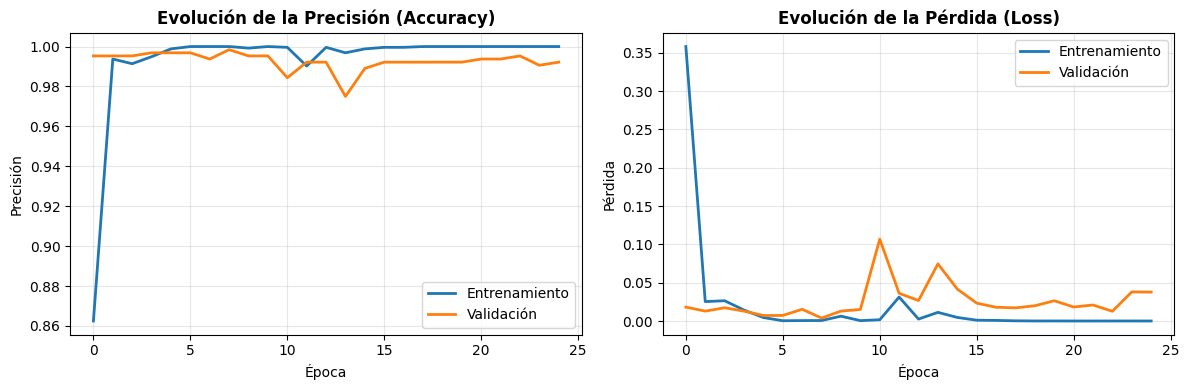

In [9]:
plt.figure(figsize=(12, 4))

# Gráfica de Precisión (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(historial.history['accuracy'], label='Entrenamiento', linewidth=2)
plt.plot(historial.history['val_accuracy'], label='Validación', linewidth=2)
plt.title('Evolución de la Precisión (Accuracy)', fontweight='bold')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend()
plt.grid(True, alpha=0.3)

# Gráfica de Pérdida (Loss)
plt.subplot(1, 2, 2)
plt.plot(historial.history['loss'], label='Entrenamiento', linewidth=2)
plt.plot(historial.history['val_loss'], label='Validación', linewidth=2)
plt.title('Evolución de la Pérdida (Loss)', fontweight='bold')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
modelo.save("detective_senales_cnn.keras")
print("Modelo guardado exitosamente en el entorno como 'detective_senales_cnn.keras'")

Modelo guardado exitosamente en el entorno como 'detective_senales_cnn.keras'


In [11]:
from tensorflow.keras.models import load_model
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# 1. Cargar el modelo persistente de la Fase 2
modelo_cargado = load_model("detective_senales_cnn.keras")
print("Modelo 'detective_senales_cnn.keras' cargado exitosamente.")

# 2. Evaluar en el conjunto de prueba (800 muestras)
perdida_test, exactitud_test = modelo_cargado.evaluate(X_test_cnn, y_test, verbose=1)
print(f"\nExactitud en conjunto de prueba (Test Accuracy): {exactitud_test * 100:.2f}%")
print(f"Pérdida en conjunto de prueba (Test Loss): {perdida_test:.4f}")

# 3. Obtener predicciones de clase
probabilidades = modelo_cargado.predict(X_test_cnn, verbose=0)
y_pred = np.argmax(probabilidades, axis=1)

Modelo 'detective_senales_cnn.keras' cargado exitosamente.
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9987 - loss: 0.0184

Exactitud en conjunto de prueba (Test Accuracy): 99.87%
Pérdida en conjunto de prueba (Test Loss): 0.0184


=== REPORTE DE CLASIFICACIÓN POR CLASE ===
              precision    recall  f1-score   support

         ASK     0.9950    1.0000    0.9975       200
         FSK     1.0000    1.0000    1.0000       200
         PSK     1.0000    0.9950    0.9975       200
      16-QAM     1.0000    1.0000    1.0000       200

    accuracy                         0.9988       800
   macro avg     0.9988    0.9988    0.9987       800
weighted avg     0.9988    0.9988    0.9987       800



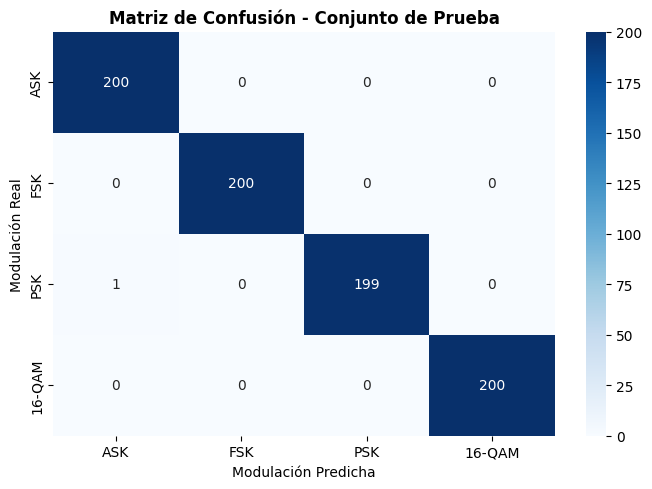

In [12]:
clases = ["ASK", "FSK", "PSK", "16-QAM"]

# Reporte de clasificación detallado
print("=== REPORTE DE CLASIFICACIÓN POR CLASE ===")
print(classification_report(y_test, y_pred, target_names=clases, digits=4))

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=clases,
    yticklabels=clases
)
plt.title("Matriz de Confusión - Conjunto de Prueba", fontweight="bold")
plt.xlabel("Modulación Predicha")
plt.ylabel("Modulación Real")
plt.tight_layout()
plt.show()

=== PRUEBAS DE ESTRÉS POR NIVEL DE SNR ===
SNR =  -5 dB  -->  Exactitud: 99.75%
SNR =   0 dB  -->  Exactitud: 100.00%
SNR =   5 dB  -->  Exactitud: 100.00%
SNR =  10 dB  -->  Exactitud: 99.75%
SNR =  15 dB  -->  Exactitud: 100.00%
SNR =  20 dB  -->  Exactitud: 100.00%


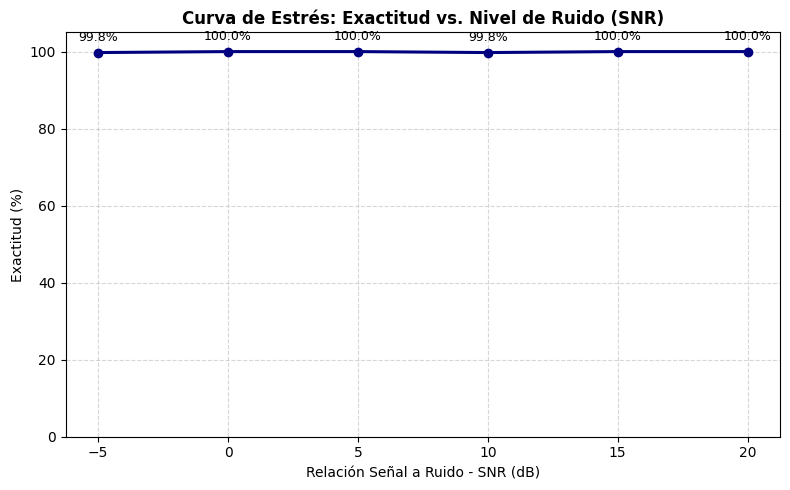

In [13]:
snr_evaluacion = [-5, 0, 5, 10, 15, 20]
exactitudes_snr = []

print("=== PRUEBAS DE ESTRÉS POR NIVEL DE SNR ===")
for snr in snr_evaluacion:
    X_test_snr = []
    for etiqueta in range(4):
        # Generamos un lote de prueba fresco con el nivel exacto de SNR
        func_gen = generadores[etiqueta]
        for _ in range(100):  # 100 por clase = 400 muestras por nivel de SNR
            sig_limpia = func_gen()
            sig_ruidosa = agregar_awgn(sig_limpia, snr)
            X_test_snr.append(sig_ruidosa)

    X_test_snr = np.array(X_test_snr).reshape((-1, total_muestras, 1))
    y_true_snr = np.repeat(np.arange(4), 100)

    _, acc_snr = modelo_cargado.evaluate(X_test_snr, y_true_snr, verbose=0)
    exactitudes_snr.append(acc_snr * 100)
    print(f"SNR = {snr:>3} dB  -->  Exactitud: {acc_snr * 100:.2f}%")

# Curva Exactitud vs. SNR (dB)
plt.figure(figsize=(8, 5))
plt.plot(snr_evaluacion, exactitudes_snr, marker="o", linewidth=2.2, color="navy")
plt.title("Curva de Estrés: Exactitud vs. Nivel de Ruido (SNR)", fontweight="bold")
plt.xlabel("Relación Señal a Ruido - SNR (dB)")
plt.ylabel("Exactitud (%)")
plt.xticks(snr_evaluacion)
plt.ylim(0, 105)
plt.grid(True, linestyle="--", alpha=0.5)

for x_val, y_val in zip(snr_evaluacion, exactitudes_snr):
    plt.annotate(f"{y_val:.1f}%", (x_val, y_val), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)

plt.tight_layout()
plt.show()

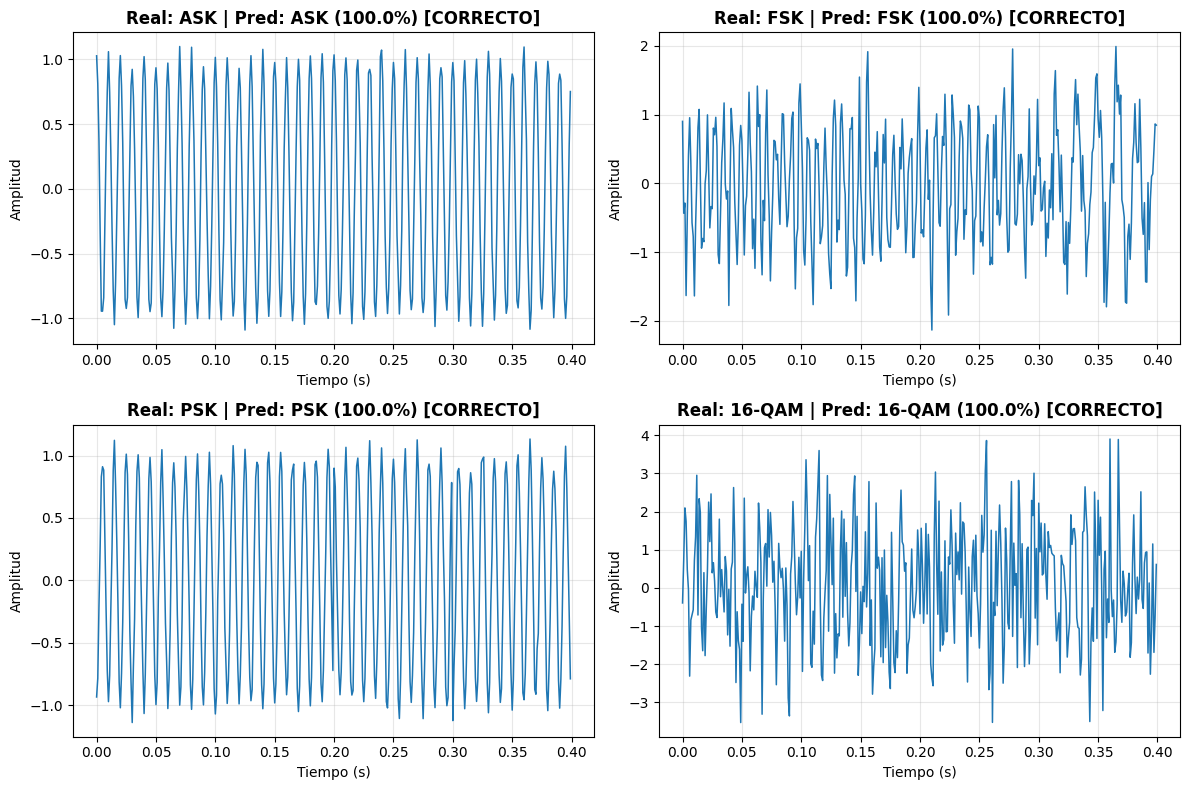

In [14]:
# Mostrar 4 muestras del conjunto de prueba (una por cada clase real)
plt.figure(figsize=(12, 8))

for idx_clase in range(4):
    idx_muestra = np.where(y_test == idx_clase)[0][0]
    senal_muestra = X_test[idx_muestra]
    real_nombre = clases[y_test[idx_muestra]]
    pred_nombre = clases[y_pred[idx_muestra]]
    confianza = probabilidades[idx_muestra][y_pred[idx_muestra]] * 100
    estado = "CORRECTO" if real_nombre == pred_nombre else "ERROR"

    plt.subplot(2, 2, idx_clase + 1)
    plt.plot(t[:400], senal_muestra[:400], linewidth=1.1)
    plt.title(f"Real: {real_nombre} | Pred: {pred_nombre} ({confianza:.1f}%) [{estado}]", fontweight="bold")
    plt.xlabel("Tiempo (s)")
    plt.ylabel("Amplitud")
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
clases = ["ASK", "FSK", "PSK", "16-QAM"]

def clasificar_senal(senal_1d, modelo):
    entrada = np.asarray(senal_1d, dtype=np.float32).reshape((1, -1, 1))
    probs = modelo.predict(entrada, verbose=0)[0]
    idx_pred = int(np.argmax(probs))
    return clases[idx_pred], float(probs[idx_pred] * 100), probs

# Pruebas con señales recién generadas a distintos niveles de SNR
escenarios = [
    (0, 20),   # ASK con buen SNR
    (1, 10),   # FSK con SNR moderado
    (2, 5),    # PSK con ruido perceptible
    (3, 0),    # 16-QAM con ruido alto
]

print("=== SIMULACIÓN DE DETECCIÓN BAJO DEMANDA ===")
for idx_real, snr_prueba in escenarios:
    senal_limpia = generadores[idx_real]()
    senal_ruidosa = agregar_awgn(senal_limpia, snr_prueba)
    pred_clase, conf, probs = clasificar_senal(senal_ruidosa, modelo_cargado)
    real_clase = clases[idx_real]
    estado = "ACIERTO" if pred_clase == real_clase else "FALLO"

    probs_str = ", ".join([f"{c}: {p*100:.1f}%" for c, p in zip(clases, probs)])
    print(f"Real: {real_clase:<6} | SNR: {snr_prueba:>3} dB | Pred: {pred_clase:<6} ({conf:5.1f}%) [{estado}]")
    print(f"   Probabilidades -> {probs_str}")

=== SIMULACIÓN DE DETECCIÓN BAJO DEMANDA ===
Real: ASK    | SNR:  20 dB | Pred: ASK    (100.0%) [ACIERTO]
   Probabilidades -> ASK: 100.0%, FSK: 0.0%, PSK: 0.0%, 16-QAM: 0.0%
Real: FSK    | SNR:  10 dB | Pred: FSK    (100.0%) [ACIERTO]
   Probabilidades -> ASK: 0.0%, FSK: 100.0%, PSK: 0.0%, 16-QAM: 0.0%
Real: PSK    | SNR:   5 dB | Pred: PSK    (100.0%) [ACIERTO]
   Probabilidades -> ASK: 0.0%, FSK: 0.0%, PSK: 100.0%, 16-QAM: 0.0%
Real: 16-QAM | SNR:   0 dB | Pred: 16-QAM (100.0%) [ACIERTO]
   Probabilidades -> ASK: 0.0%, FSK: 0.0%, PSK: 0.0%, 16-QAM: 100.0%


In [16]:
import time

# 1. Latencia promedio por señal individual (sobre 100 señales)
muestras_prueba = X_test_cnn[:100]
t_inicio = time.perf_counter()
for i in range(len(muestras_prueba)):
    _ = modelo_cargado.predict(muestras_prueba[i:i+1], verbose=0)
t_fin = time.perf_counter()

tiempo_total_ms = (t_fin - t_inicio) * 1000
latencia_por_senal_ms = tiempo_total_ms / len(muestras_prueba)

# 2. Tiempo en lote completo (800 señales de prueba)
t_lote_inicio = time.perf_counter()
_ = modelo_cargado.predict(X_test_cnn, batch_size=32, verbose=0)
t_lote_fin = time.perf_counter()
tiempo_lote_ms = (t_lote_fin - t_lote_inicio) * 1000

print("=== RENDIMIENTO Y LATENCIA DEL MODELO ===")
print(f"Tiempo promedio por señal individual (100 muestras): {latencia_por_senal_ms:.2f} ms")
print(f"Tiempo para lote completo de prueba ({len(X_test_cnn)} muestras): {tiempo_lote_ms:.2f} ms")
print(f"Rendimiento aproximado en lote: {(len(X_test_cnn) / (tiempo_lote_ms / 1000)):.0f} señales/seg")

=== RENDIMIENTO Y LATENCIA DEL MODELO ===
Tiempo promedio por señal individual (100 muestras): 108.34 ms
Tiempo para lote completo de prueba (800 muestras): 747.87 ms
Rendimiento aproximado en lote: 1070 señales/seg


=== ANÁLISIS DE CONFIANZA (SOFTMAX) ===
Total de aciertos: 799 / 800 | Confianza promedio: 100.00%
Total de errores:  1 / 800 | Confianza promedio: 100.00%


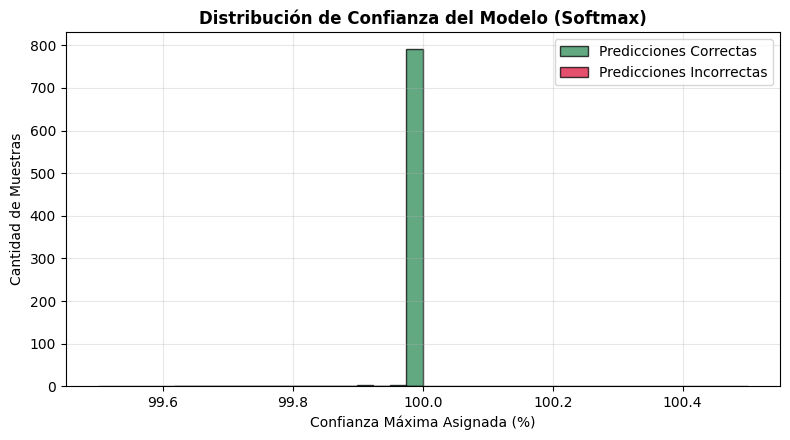

In [17]:
probabilidades_test = modelo_cargado.predict(X_test_cnn, verbose=0)
y_pred_test = np.argmax(probabilidades_test, axis=1)
confianzas_max = np.max(probabilidades_test, axis=1) * 100

mascara_aciertos = (y_pred_test == y_test)
mascara_errores = ~mascara_aciertos

conf_aciertos = confianzas_max[mascara_aciertos]
conf_errores = confianzas_max[mascara_errores]

print("=== ANÁLISIS DE CONFIANZA (SOFTMAX) ===")
print(f"Total de aciertos: {np.sum(mascara_aciertos)} / {len(y_test)} | Confianza promedio: {np.mean(conf_aciertos):.2f}%")
if np.sum(mascara_errores) > 0:
    print(f"Total de errores:  {np.sum(mascara_errores)} / {len(y_test)} | Confianza promedio: {np.mean(conf_errores):.2f}%")
else:
    print("Total de errores:  0 / 800 (100% de aciertos en el conjunto de prueba)")

plt.figure(figsize=(8, 4.5))
plt.hist(conf_aciertos, bins=15, alpha=0.75, label="Predicciones Correctas", color="seagreen", edgecolor="black")
if np.sum(mascara_errores) > 0:
    plt.hist(conf_errores, bins=15, alpha=0.75, label="Predicciones Incorrectas", color="crimson", edgecolor="black")
plt.title("Distribución de Confianza del Modelo (Softmax)", fontweight="bold")
plt.xlabel("Confianza Máxima Asignada (%)")
plt.ylabel("Cantidad de Muestras")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Archivo 'detective_senales_cnn.keras' existe: True | Tamaño: 24466.4 KB


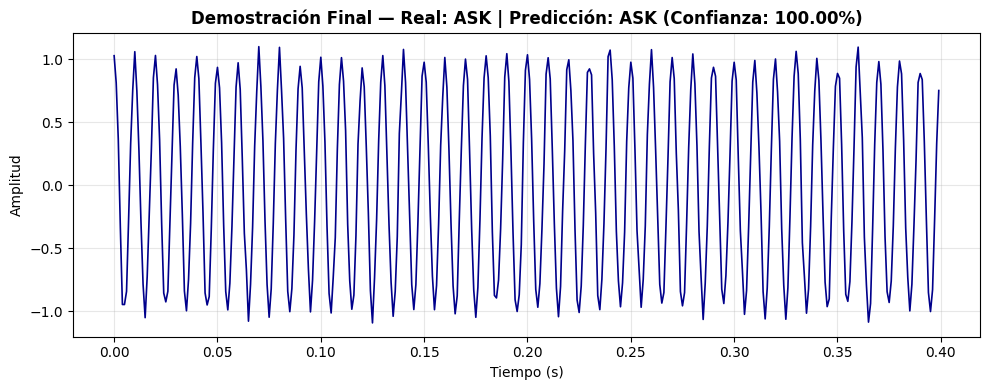

In [18]:
import os

# Verificación del archivo persistente
ruta_modelo = "detective_senales_cnn.keras"
existe = os.path.exists(ruta_modelo)
tamano_kb = os.path.getsize(ruta_modelo) / 1024 if existe else 0
print(f"Archivo '{ruta_modelo}' existe: {existe} | Tamaño: {tamano_kb:.1f} KB")

# Demostración visual de una señal evaluada
idx_demo = 0
senal_demo = X_test[idx_demo]
real_demo = clases[y_test[idx_demo]]
pred_demo, conf_demo, probs_demo = clasificar_senal(senal_demo, modelo_cargado)

plt.figure(figsize=(10, 4))
plt.plot(t[:400], senal_demo[:400], linewidth=1.2, color="darkblue")
plt.title(
    f"Demostración Final — Real: {real_demo} | Predicción: {pred_demo} (Confianza: {conf_demo:.2f}%)",
    fontweight="bold"
)
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()